In [2]:
##Step 1:
##Import the required libraries: OpenCV, NumPy, and Matplotlib.

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
Step 2:
Read the image n14.jpg in grayscale format.

In [7]:
gray = cv2.imread('n14.jpg', cv2.IMREAD_GRAYSCALE)

In [ ]:
Step 3:
Display the grayscale image and plot its histogram.

C:\Users\Admin\AppData\Local\Temp\ipykernel_7556\2446054334.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(gray.ravel(), 256, [0, 256])


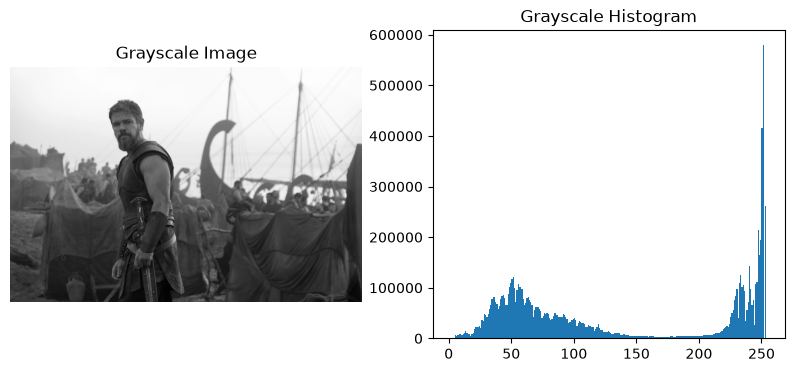

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(gray.ravel(), 256, [0, 256])
plt.title('Grayscale Histogram')

plt.show()

In [ ]:
Step 4:
Apply histogram equalization using cv2.equalizeHist() to enhance contrast.

In [9]:
equalized = cv2.equalizeHist(gray)

In [ ]:
Step 5:
Display original grayscale image, its histogram, enhanced image, and its histogram using a 2 × 2 grid.

C:\Users\Admin\AppData\Local\Temp\ipykernel_7556\3079960104.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(gray.ravel(), 256, [0, 256])
C:\Users\Admin\AppData\Local\Temp\ipykernel_7556\3079960104.py:18: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(equalized.ravel(), 256, [0, 256])


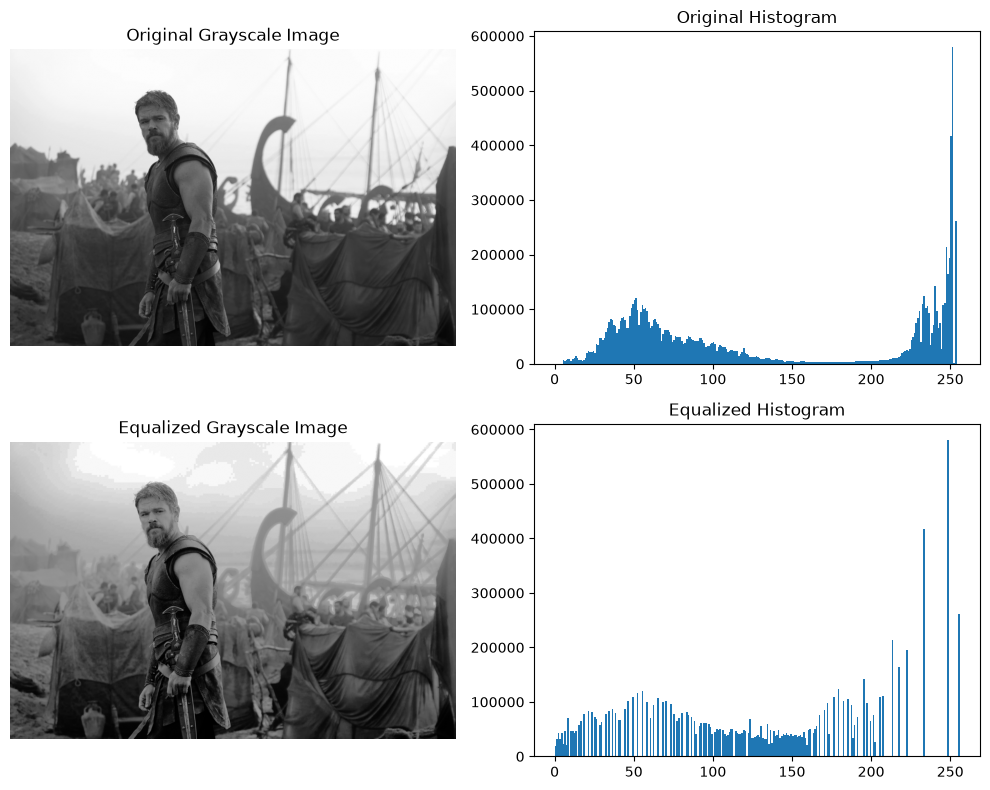

In [10]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.hist(gray.ravel(), 256, [0, 256])
plt.title('Original Histogram')

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap='gray')
plt.title('Equalized Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title('Equalized Histogram')

plt.tight_layout()
plt.show()

In [ ]:
Step 6:
Read the same image in color format.

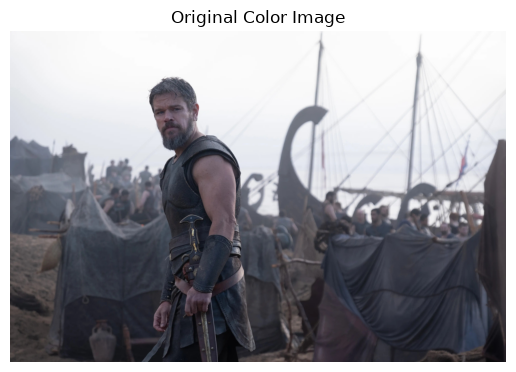

In [11]:
img = cv2.imread('n14.jpg')

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Color Image')
plt.axis('off')
plt.show()

In [ ]:
Step 7:
Split the image into B, G, R channels and plot their histograms.

C:\Users\Admin\AppData\Local\Temp\ipykernel_15228\306215831.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(b.ravel(), 256, [0, 256], color='blue', label='Blue')
C:\Users\Admin\AppData\Local\Temp\ipykernel_15228\306215831.py:6: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(g.ravel(), 256, [0, 256], color='green', label='Green')
C:\Users\Admin\AppData\Local\Temp\ipykernel_15228\306215831.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(r.ravel(), 256, [0, 256], color='red', label='Red')


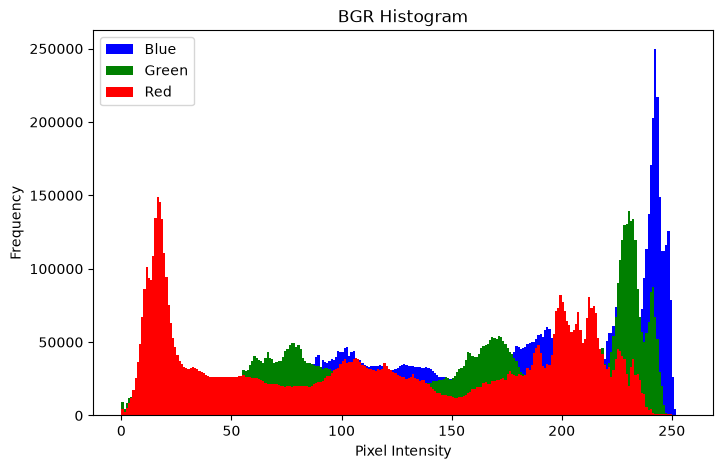

In [8]:
b, g, r = cv2.split(img)

plt.figure(figsize=(8, 5))

plt.hist(b.ravel(), 256, [0, 256], color='blue', label='Blue')
plt.hist(g.ravel(), 256, [0, 256], color='green', label='Green')
plt.hist(r.ravel(), 256, [0, 256], color='red', label='Red')

plt.title('BGR Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [ ]:
Step 8:
Convert the image from BGR to HSV color space.

In [12]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(hsv)

In [ ]:
Step 9:
Apply histogram equalization on the V (Value) channel.

In [13]:
v_equalized = cv2.equalizeHist(v)

In [ ]:
Step 10:
Merge the channels and convert the image back to BGR format.

In [14]:
hsv_equalized = cv2.merge((h, s, v_equalized))

enhanced = cv2.cvtColor(hsv_equalized, cv2.COLOR_HSV2BGR)

In [ ]:
Step 11:
Display original color image, histogram, enhanced image, and enhanced histogram using a 2 × 2 grid.

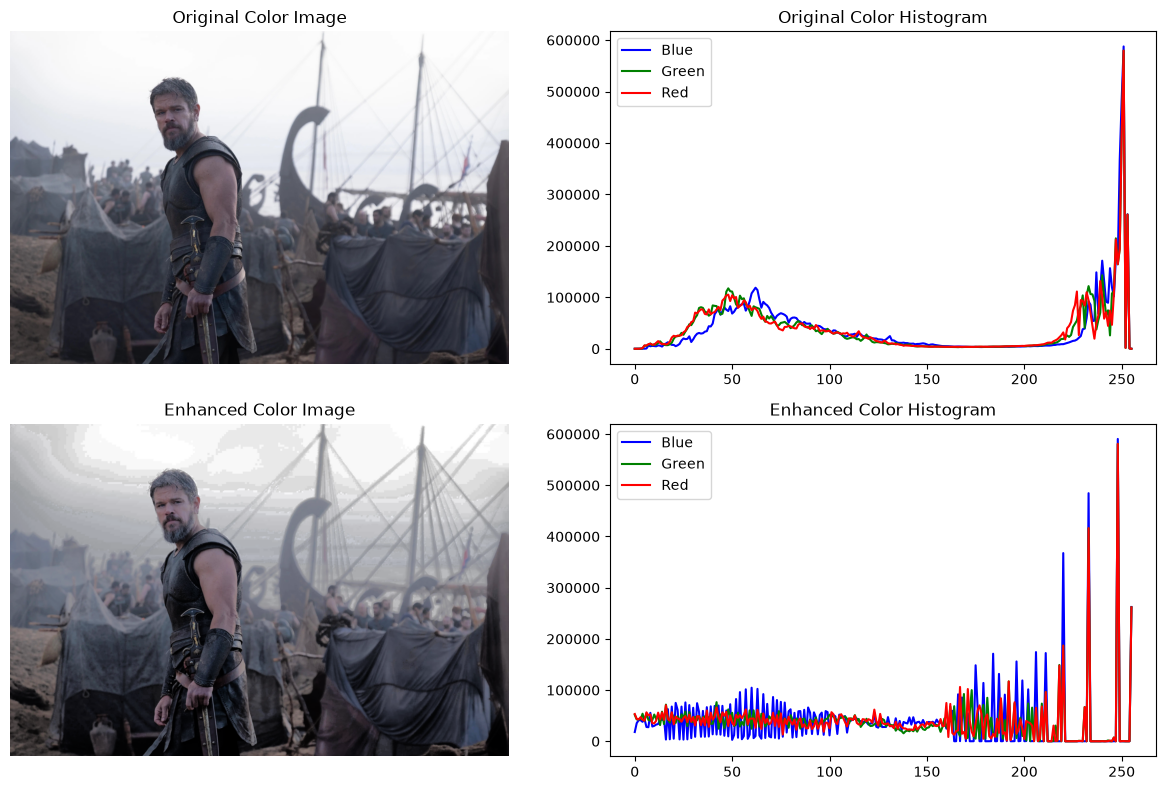

In [15]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Color Image')
plt.axis('off')

plt.subplot(2, 2, 2)
for channel, color, name in zip(cv2.split(img),
                                 ['blue', 'green', 'red'],
                                 ['Blue', 'Green', 'Red']):
    hist = cv2.calcHist([img], [ [ 'Blue', 'Green', 'Red' ].index(name) ],
                        None, [256], [0, 256])
    plt.plot(hist, color=color, label=name)

plt.title('Original Color Histogram')
plt.legend()

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(enhanced, cv2.COLOR_BGR2RGB))
plt.title('Enhanced Color Image')
plt.axis('off')

plt.subplot(2, 2, 4)
for i, color in enumerate(['blue', 'green', 'red']):
    hist = cv2.calcHist([enhanced], [i], None, [256], [0, 256])
    plt.plot(hist, color=color, label=color.capitalize())

plt.title('Enhanced Color Histogram')
plt.legend()

plt.tight_layout()
plt.show()